# Prototype Simplest Runner

**Objective.** Verify that the current package can load Flowers102, train a GDFM UNet, and generate finite samples.

**Success criteria.** Local data loads, optimizer steps finish, losses stay finite, and sampling returns finite image tensors.

**Scope.** Two epochs on 64 images test the pipeline only. The generated images do not need to look realistic.

In [ ]:
# Purpose: Import the required packages and select one compute device.
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset

# Find the repository from either its root
# or the notebook directory.
REPO_ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "mem_param_src").is_dir()
)
sys.path.insert(0, str(REPO_ROOT))

from mem_param_src.config import get_base_config
from mem_param_src.datasets import build_data_bundle
from mem_param_src.model import GDFM

DATA_ROOT = REPO_ROOT / "data"
RUN_DIR = REPO_ROOT / "outputs" / "prototypes" / "simplest_runner_flowers102"
RUN_DIR.mkdir(parents=True, exist_ok=True)

torch.manual_seed(7)  # Control model initialization and training noise.

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"device: {device}")
print(f"run directory: {RUN_DIR}")

device: mps
run directory: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/prototypes/simplest_runner_flowers102


In [30]:
# Purpose: Define one small Flowers102 flow-matching experiment.
cfg = get_base_config()

cfg.study.name = "prototype_simplest_runner"
cfg.study.dataset_key = "flowers102"
cfg.outputs.run_name = "prototype_simplest_runner"

# Predict velocity and compute the loss in velocity space.
cfg.framework.family = "fm"
cfg.framework.prediction_space = "v"
cfg.framework.loss_space = "v"
cfg.framework.loss_weighting = "unit"

# Use deterministic subsets from two official Flowers102 splits.
cfg.data.dataset = "flowers102"
cfg.data.root = str(DATA_ROOT)
cfg.data.download = False
cfg.data.train_split = "train"
cfg.data.reference_split = "val"
cfg.data.n_train = 4
cfg.data.n_test = 16
cfg.data.image_size = 32
cfg.data.resize_size = 32
cfg.data.image_channels = 3
cfg.data.flatten = False

# Use the smallest valid two-level configuration for the current UNet.
cfg.network.arch = "unet"
cfg.network.base_channels = 32
cfg.network.channel_mult = (1, 2)
cfg.network.attn_resolutions = ()
cfg.network.num_res_blocks = 1
cfg.network.dropout = 0.0

cfg.training.seed = 7
cfg.training.batch_size = 8
cfg.training.lr = 1.0e-3
cfg.training.weight_decay = 0.0

cfg.sampling.method = "heun"
cfg.sampling.n_steps = 100
cfg.sampling.start_time = 0.01
cfg.sampling.end_time = 0.99
cfg.sampling.use_safe_division = False
cfg.sampling.safe_div_denom_eps = 0.01
cfg.sampling.output = "x_t_max"

N_EPOCHS = 2000
N_SAMPLES = 4

In [31]:
# Purpose: Load the exact training subset and construct shuffled mini-batches.
bundle = build_data_bundle(cfg)
train_tensor = bundle["train"]

assert train_tensor.shape == (cfg.data.n_train, 3, 32, 32)
assert float(train_tensor.min()) >= -1.0
assert float(train_tensor.max()) <= 1.0

loader_generator = torch.Generator().manual_seed(int(cfg.training.seed))
train_loader = DataLoader(
    TensorDataset(train_tensor),
    batch_size=int(cfg.training.batch_size),
    shuffle=True,
    generator=loader_generator,
    num_workers=0,  # Keep notebook loading predictable.
)

# Save the exact tensors and indices used by this prototype.
torch.save(
    {
        "train": bundle["train"],
        "train_labels": bundle["train_labels"],
        "train_indices": bundle["train_indices"],
        "reference": bundle["reference"],
        "reference_labels": bundle["reference_labels"],
        "reference_indices": bundle["reference_indices"],
    },
    RUN_DIR / "data_bundle.pt",
)

print(f"training tensor: {tuple(train_tensor.shape)}")
print(f"training batches per epoch: {len(train_loader)}")
print(
    f"value range: [{float(train_tensor.min()):.3f}, {float(train_tensor.max()):.3f}]"
)

training tensor: (4, 3, 32, 32)
training batches per epoch: 1
value range: [-1.000, 0.992]


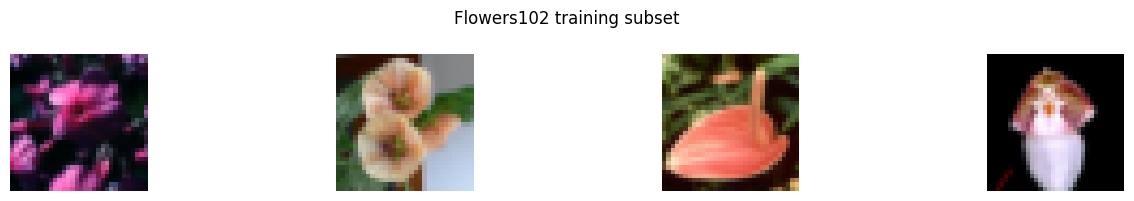

In [32]:
# Purpose: Display examples from the exact tensor used for training.
display_images = train_tensor[:N_SAMPLES].add(1.0).div(2.0).clamp(0.0, 1.0)

fig, axes = plt.subplots(1, N_SAMPLES, figsize=(14, 2))
for index, axis in enumerate(axes):
    axis.imshow(display_images[index].permute(1, 2, 0))
    axis.axis("off")

fig.suptitle("Flowers102 training subset")
plt.tight_layout()
fig.savefig(RUN_DIR / "training_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
# Purpose: Build the GDFM model and its Adam optimizer.
model = GDFM(cfg).to(device)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=float(cfg.training.lr),
    weight_decay=float(cfg.training.weight_decay),
)

print(f"model parameters: {model.n_params():,}")
print(f"prediction/loss spaces: {model.prediction_space}/{model.loss_space}")

model parameters: 669,251
prediction/loss spaces: v/v


In [34]:
# Purpose: Optimize the model for two complete passes over the subset.
step_losses = []
model.train()

for epoch in range(1, N_EPOCHS + 1):
    epoch_loss = 0.0

    for (batch,) in train_loader:
        batch = batch.to(device)

        optimizer.zero_grad(set_to_none=True)
        loss = model.compute_loss(batch)
        loss.backward()
        optimizer.step()

        loss_value = float(loss.item())
        assert torch.isfinite(loss)
        step_losses.append(loss_value)
        epoch_loss += loss_value

    mean_loss = epoch_loss / len(train_loader)
    print(f"epoch {epoch}/{N_EPOCHS} | mean loss: {mean_loss:.6f}")

epoch 1/2000 | mean loss: 1.472353
epoch 2/2000 | mean loss: 1.432028
epoch 3/2000 | mean loss: 1.339073
epoch 4/2000 | mean loss: 1.285084
epoch 5/2000 | mean loss: 1.336386
epoch 6/2000 | mean loss: 1.237414
epoch 7/2000 | mean loss: 1.178697
epoch 8/2000 | mean loss: 1.190427
epoch 9/2000 | mean loss: 1.089795
epoch 10/2000 | mean loss: 1.125824
epoch 11/2000 | mean loss: 1.106531
epoch 12/2000 | mean loss: 1.015946
epoch 13/2000 | mean loss: 0.989385
epoch 14/2000 | mean loss: 0.900634
epoch 15/2000 | mean loss: 0.930181
epoch 16/2000 | mean loss: 0.928293
epoch 17/2000 | mean loss: 0.873405
epoch 18/2000 | mean loss: 0.872245
epoch 19/2000 | mean loss: 0.827680
epoch 20/2000 | mean loss: 0.807895
epoch 21/2000 | mean loss: 0.805269
epoch 22/2000 | mean loss: 0.898590
epoch 23/2000 | mean loss: 0.773893
epoch 24/2000 | mean loss: 0.714222
epoch 25/2000 | mean loss: 0.756556
epoch 26/2000 | mean loss: 0.672049
epoch 27/2000 | mean loss: 0.688261
epoch 28/2000 | mean loss: 0.666093
e

In [48]:
# Purpose: Generate images from fixed noise and save the replay artifacts.
noise_generator = torch.Generator().manual_seed(12321)
z_init = torch.randn(
    N_SAMPLES,
    int(cfg.data.image_channels),
    int(cfg.data.image_size),
    int(cfg.data.image_size),
    generator=noise_generator,
)

torch.save(z_init, RUN_DIR / "z_init.pt")

model.eval()
samples = model.sample(
    z_init.to(device),
    n_steps=int(cfg.sampling.n_steps),
    method=str(cfg.sampling.method),
    start_time=float(cfg.sampling.start_time),
    end_time=float(cfg.sampling.end_time),
    use_safe_division=bool(cfg.sampling.use_safe_division),
    safe_div_denom_eps=float(cfg.sampling.safe_div_denom_eps),
    output=str(cfg.sampling.output),
    device=device,
).cpu()

assert samples.shape == z_init.shape
assert torch.isfinite(samples).all()

torch.save(samples, RUN_DIR / "samples.pt")
torch.save(
    {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "epochs": N_EPOCHS,
        "step_losses": step_losses,
    },
    RUN_DIR / "checkpoint.pt",
)

print(f"sample tensor: {tuple(samples.shape)}")
print(f"all samples finite: {bool(torch.isfinite(samples).all())}")

sample tensor: (4, 3, 32, 32)
all samples finite: True


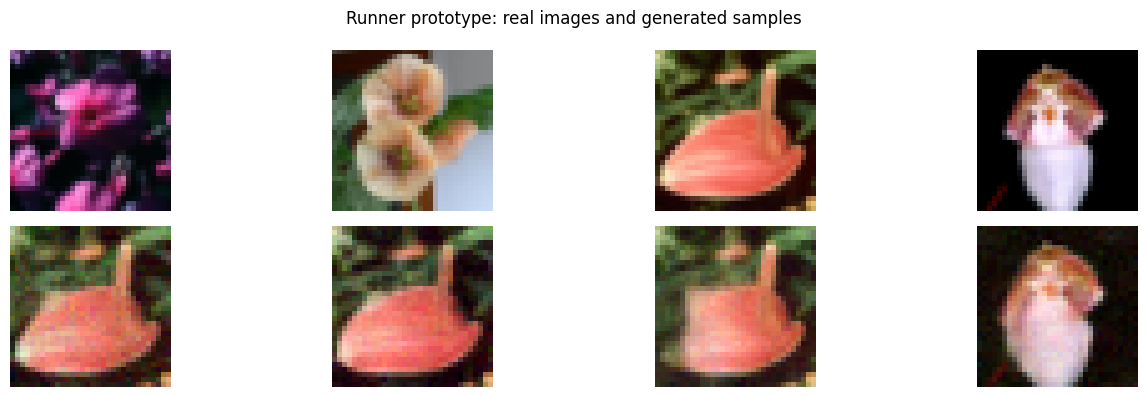

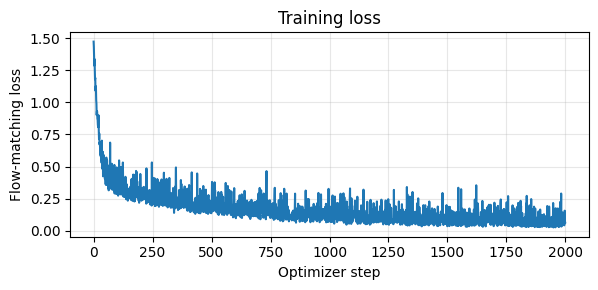

{'device': 'mps',
 'optimizer_steps': 2000,
 'first_loss': 1.4723529815673828,
 'last_loss': 0.06476405262947083,
 'sample_shape': (4, 3, 32, 32),
 'samples_finite': True}

In [52]:
# Purpose: Compare training images with samples and plot the training loss.
real_display = train_tensor[:N_SAMPLES].add(1.0).div(2.0).clamp(0.0, 1.0)
sample_display = samples.add(1.0).div(2.0).clamp(0.0, 1.0)

fig, axes = plt.subplots(2, N_SAMPLES, figsize=(14, 4))

for index in range(N_SAMPLES):
    axes[0, index].imshow(real_display[index].permute(1, 2, 0))
    axes[0, index].axis("off")

    axes[1, index].imshow(sample_display[index].permute(1, 2, 0))
    axes[1, index].axis("off")

axes[0, 0].set_ylabel("Training", rotation=0, labelpad=35)
axes[1, 0].set_ylabel("Generated", rotation=0, labelpad=35)
fig.suptitle("Runner prototype: real images and generated samples")
plt.tight_layout()
fig.savefig(RUN_DIR / "training_and_samples.png", dpi=150, bbox_inches="tight")
plt.show()

loss_figure, loss_axis = plt.subplots(figsize=(6, 3))
loss_axis.plot(step_losses)
loss_axis.set_xlabel("Optimizer step")
loss_axis.set_ylabel("Flow-matching loss")
loss_axis.set_title("Training loss")
loss_axis.grid(alpha=0.3)
loss_figure.tight_layout()
loss_figure.savefig(RUN_DIR / "training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

result = {
    "device": str(device),
    "optimizer_steps": len(step_losses),
    "first_loss": step_losses[0],
    "last_loss": step_losses[-1],
    "sample_shape": tuple(samples.shape),
    "samples_finite": bool(torch.isfinite(samples).all()),
}
result